# De Laval Nozzle — Thrust Analysis

**Research question:** How do ambient pressure and nozzle exit-to-throat area ratio affect predicted thrust?

The study compares five nozzle area ratios using a one-dimensional, steady, isentropic air-flow model. The results are numerical predictions, not experimental measurements or CFD simulations.

## 1. Model parameters

All calculations use SI units. Chamber conditions, throat area, and constant air properties are **assumed inputs**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

# Fixed inputs (SI units)
gamma = 1.4
R = 287.0       # J/(kg K)
P0 = 1_000_000  # Pa (chamber stagnation pressure)
T0 = 300.0     # K  (chamber stagnation temperature)
At = 0.01      # m^2 (throat area)

area_ratios = [2, 3, 4, 5, 6]
ambient_pressures = np.linspace(101_325, 0, 101)  # Pa, sea level to vacuum
print(f"Ambient pressure samples: {len(ambient_pressures)}")

Ambient pressure samples: 101


## 2. Exit Mach number

For a choked throat, the supersonic exit Mach number is obtained from the area–Mach relation:

$$\frac{A_e}{A_t}=\frac{1}{M_e}\left[\frac{2}{\gamma+1}\left(1+\frac{\gamma-1}{2}M_e^2\right)\right]^{\frac{\gamma+1}{2(\gamma-1)}}.$$

A grid search is compared with Brent's root-finding method; Brent's result is used in subsequent calculations.

In [2]:
def area_mach(M):
    return (1 / M) * (
        (2 / (gamma + 1)) * (1 + (gamma - 1) * M**2 / 2)
    ) ** ((gamma + 1) / (2 * (gamma - 1)))

mach_grid = np.linspace(1.001, 10, 10_000)
exit_machs_grid = np.array([
    mach_grid[np.argmin(np.abs(area_mach(mach_grid) - ar))]
    for ar in area_ratios
])
exit_machs = np.array([
    brentq(lambda M: area_mach(M) - ar, 1.001, 10)
    for ar in area_ratios
])

print("AR   Grid Mach    Brent Mach    Absolute difference")
for ar, grid_M, exact_M in zip(area_ratios, exit_machs_grid, exit_machs):
    print(f"{ar:<4} {grid_M:10.6f}  {exact_M:11.6f}  {abs(grid_M-exact_M):.6f}")
assert np.max(np.abs(exit_machs_grid - exit_machs)) < 0.0004
assert np.allclose(area_mach(exit_machs), area_ratios, atol=1e-9)

AR   Grid Mach    Brent Mach    Absolute difference
2      2.197087     2.197198  0.000111
3      2.637182     2.637416  0.000234
4      2.940478     2.940179  0.000299
5      3.174476     3.174780  0.000304
6      3.367974     3.367872  0.000101


## 3. Exit conditions and mass flow

Using the isentropic relations:

$$P_e=P_0\left(1+\frac{\gamma-1}{2}M_e^2\right)^{-\gamma/(\gamma-1)}$$

$$T_e=\frac{T_0}{1+\frac{\gamma-1}{2}M_e^2},\qquad V_e=M_e\sqrt{\gamma RT_e}.$$

For choked flow, the mass flow rate is:

$$\dot m=A_tP_0\sqrt{\frac{\gamma}{RT_0}}\left(\frac{2}{\gamma+1}\right)^{\frac{\gamma+1}{2(\gamma-1)}}.$$


In [3]:
exit_areas = At * np.array(area_ratios)
exit_pressures = P0 * (1 + (gamma - 1) * exit_machs**2 / 2) ** (-gamma / (gamma - 1))
exit_temperatures = T0 / (1 + (gamma - 1) * exit_machs**2 / 2)
exit_velocities = exit_machs * np.sqrt(gamma * R * exit_temperatures)

mass_flow = (
    At * P0 * np.sqrt(gamma / (R * T0))
    * (2 / (gamma + 1)) ** ((gamma + 1) / (2 * (gamma - 1)))
)
print(f"Choked mass flow rate: {mass_flow:.5f} kg/s")
print("AR   Exit Mach  Pe (kPa)  Te (K)  Ve (m/s)")
for i, ar in enumerate(area_ratios):
    print(f"{ar:<4} {exit_machs[i]:9.5f} {exit_pressures[i]/1e3:9.3f} "
          f"{exit_temperatures[i]:8.2f} {exit_velocities[i]:9.2f}")

Choked mass flow rate: 23.33559 kg/s
AR   Exit Mach  Pe (kPa)  Te (K)  Ve (m/s)
2      2.19720    93.933   152.63    544.12
3      2.63742    47.299   125.46    592.16
4      2.94018    29.787   109.93    617.94
5      3.17478    20.993    99.47    634.71
6      3.36787    15.841    91.78    646.76


## 4. Thrust calculation

$$F=\dot m V_e+(P_e-P_{amb})A_e.$$

The model evaluates 101 ambient pressures from 101.325 kPa to vacuum. For fixed nozzle geometry and chamber conditions, thrust is linear in ambient pressure.

In [4]:
momentum_thrust = mass_flow * exit_velocities

# Each array contains 101 calculated thrust values, one for each ambient pressure.
all_thrusts = []
for i, ar in enumerate(area_ratios):
    pressure_thrust = (exit_pressures[i] - ambient_pressures) * exit_areas[i]
    total_thrust = momentum_thrust[i] + pressure_thrust
    all_thrusts.append(total_thrust)

print("AR  Sea level (kN)  Vacuum (kN)  Pe (kPa)")
for i, ar in enumerate(area_ratios):
    print(f"{ar:<3} {all_thrusts[i][0]/1e3:14.4f} "
          f"{all_thrusts[i][-1]/1e3:12.4f} "
          f"{exit_pressures[i]/1e3:9.4f}")

# Basic invariants that catch common mistakes.
assert all(np.all(np.diff(F) > 0) for F in all_thrusts)
assert abs(all_thrusts[2][0] - 11558.36495) < 0.1
assert abs(all_thrusts[2][-1] - 15611.36495) < 0.1

AR  Sea level (kN)  Vacuum (kN)  Pe (kPa)
2          12.5495      14.5760   93.9326
3          12.1975      15.2373   47.2987
4          11.5584      15.6114   29.7870
5          10.7947      15.8609   20.9927
6           9.9636      16.0431   15.8407


## 5. Thrust comparison

Predicted ideal thrust for area ratios 2–6.

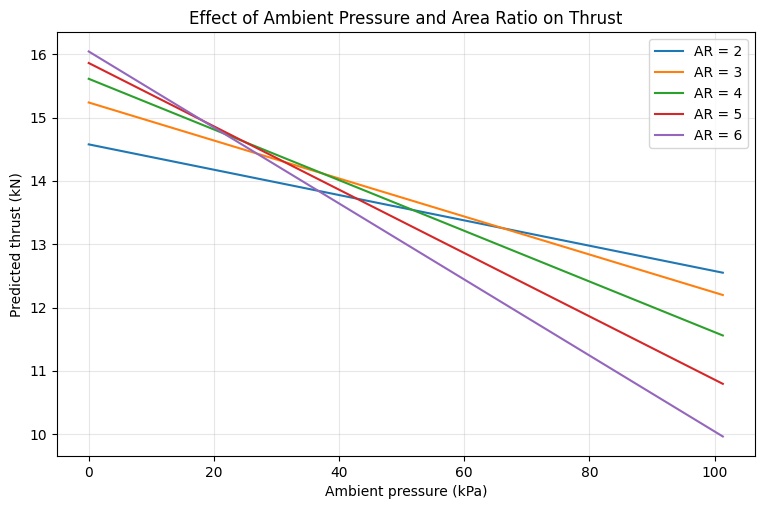

In [5]:
fig, ax = plt.subplots(figsize=(9, 5.5))
for i, ar in enumerate(area_ratios):
    ax.plot(ambient_pressures / 1000, all_thrusts[i] / 1000, label=f"AR = {ar}")
ax.set_xlabel("Ambient pressure (kPa)")
ax.set_ylabel("Predicted thrust (kN)")
ax.set_title("Effect of Ambient Pressure and Area Ratio on Thrust")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

## 6. Expansion regimes for AR = 4

- **Overexpanded:** $P_e<P_{amb}$
- **Pressure matched:** $P_e=P_{amb}$
- **Underexpanded:** $P_e>P_{amb}$

The classification is based on ideal exit-pressure matching. The sampled grid may contain no exactly matched point.

AR = 4 pressure-matching ambient pressure: 29.7870 kPa
Overexpanded: 71 sampled pressures
Optimal: 0 sampled pressures
Underexpanded: 30 sampled pressures


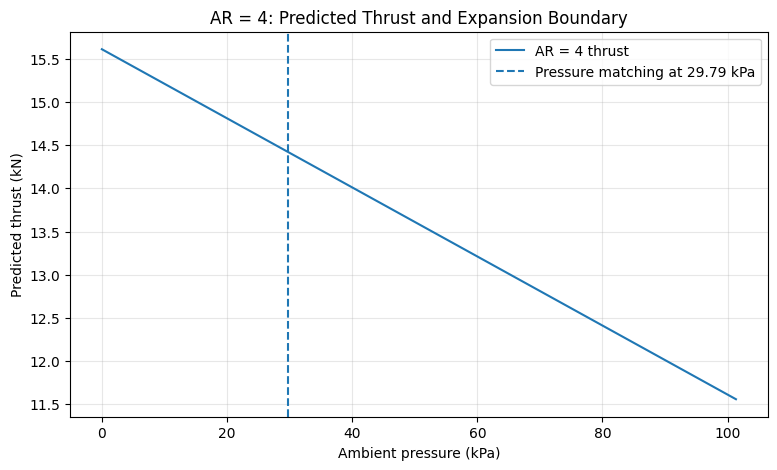

In [6]:
i4 = area_ratios.index(4)
pe4 = exit_pressures[i4]
regimes = np.where(ambient_pressures > pe4, "Overexpanded",
                   np.where(ambient_pressures < pe4, "Underexpanded", "Optimal"))
print(f"AR = 4 pressure-matching ambient pressure: {pe4 / 1000:.4f} kPa")
for name in ("Overexpanded", "Optimal", "Underexpanded"):
    print(f"{name}: {np.count_nonzero(regimes == name)} sampled pressures")

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(ambient_pressures / 1000, all_thrusts[i4] / 1000, label="AR = 4 thrust")
ax.axvline(pe4 / 1000, ls="--", label=f"Pressure matching at {pe4/1000:.2f} kPa")
ax.set_xlabel("Ambient pressure (kPa)")
ax.set_ylabel("Predicted thrust (kN)")
ax.set_title("AR = 4: Predicted Thrust and Expansion Boundary")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

## 7. CAD dimensions

For circular nozzle sections:

$$r_e=r_t\sqrt{AR},\qquad r_t=\sqrt{A_t/\pi}.$$

The Onshape geometry uses a fixed throat radius and varies the exit radius. The remaining CAD dimensions do not enter this one-dimensional thrust calculation.

In [7]:
throat_radius_mm = np.sqrt(At / np.pi) * 1000
print(f"Throat inner radius: {throat_radius_mm:.3f} mm")
print("AR   Exit inner radius (mm)   Exit inner diameter (mm)")
for ar in area_ratios:
    re_mm = throat_radius_mm * np.sqrt(ar)
    print(f"{ar:<4} {re_mm:21.2f} {2*re_mm:26.2f}")

Throat inner radius: 56.419 mm
AR   Exit inner radius (mm)   Exit inner diameter (mm)
2                    79.79                     159.58
3                    97.72                     195.44
4                   112.84                     225.68
5                   126.16                     252.31
6                   138.20                     276.40


## 8. Findings and limitations

- At 101.325 kPa ambient pressure, AR = 2 has the highest predicted thrust among the cases studied.
- In the vacuum limit, AR = 6 has the highest predicted thrust.
- Lower ambient pressure increases predicted thrust at each fixed area ratio under the model assumptions.

**Limitations:** This idealized model omits viscous effects, shock waves, boundary layers, flow separation, and changing gas properties. It does not establish actual engine performance.

**References:** [NASA Glenn — Thrust equations](https://www1.grc.nasa.gov/beginners-guide-to-aeronautics/thrust-equations-summary/), [Mass flow](https://www1.grc.nasa.gov/beginners-guide-to-aeronautics/mass-flow-rate-equations/), [Nozzle design](https://www1.grc.nasa.gov/beginners-guide-to-aeronautics/nozzle-design/); [SciPy brentq](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.brentq.html).

*Documentation and notebook organization were edited with AI assistance.*